# 未知人群周围的引导代理部署：Step 1 演示与实验报告
**Adaptive Guide-Agent Deployment for Unknown Dynamic Crowds**

**报告日期：2026-10-14｜案例：50 名静态人员、8 个 Guide｜部署方法：Equal Arc**

本 Notebook 按“说明 → 代码 → 图表 → 解读”的顺序，演示一次完整静态部署：
从人员观测建立保守包络，生成部署目标，执行安全运动，保存轨迹，再独立复判。
文件已保留实际执行输出，打开后可以直接阅读。重新执行时会产生一个新的实验目录。

**本次目标：验证一个固定案例的完整部署流程。** 单次成功不代表随机场景成功率、真实人群遏制效果、
动态人群控制或任意初态必达；这些需要后续独立实验。

---

## 0. 使用方法与运行环境：uv venv

1. 将本文件放在项目根目录或其 `notebooks/` 目录中，用 Cursor／Jupyter 打开。
2. 选择项目 `.venv` 中的 Python；Windows 对应 `.venv\Scripts\python.exe`。
3. 按顺序运行单元格，或使用 **Run All**。

**已有 `.venv` 时直接使用，无需重新创建。** 下面命令在项目根目录执行。
项目要求 Python 3.12；首次创建环境时运行：

```bash
uv venv --python 3.12
```

安装项目和 Notebook 依赖，明确指定项目环境：

```bash
uv pip install --python .venv -e ".[dev,analysis]" ipykernel jupyterlab
```

**Cursor：** 打开本文件，在右上角 **Select Kernel → Python Environments** 中选择项目的 `.venv`。
如需注册一个容易识别的内核，Windows PowerShell 运行：

```powershell
.\.venv\Scripts\python.exe -m ipykernel install --user --name udc-step1-uv --display-name "UDC Step1 (.venv)"
```

然后选择 **UDC Step1 (.venv)**。Linux/macOS 对应命令：

```bash
.venv/bin/python -m ipykernel install --user --name udc-step1-uv --display-name "UDC Step1 (.venv)"
```

需要浏览器界面的 JupyterLab 时，Windows PowerShell 使用：

```powershell
.\.venv\Scripts\python.exe -m jupyterlab
```

Linux/macOS 使用 `.venv/bin/python -m jupyterlab`。
如果 Notebook 不在项目附近，在下面单元格的 `PROJECT_ROOT_OVERRIDE` 中填写实际项目路径。
本报告依据提交为 `56f0197`；源码变化后，应把新结果作为新版本实验记录。

参考：[uv 环境文档](https://docs.astral.sh/uv/pip/environments/)和
[uv 与 Jupyter](https://docs.astral.sh/uv/guides/integration/jupyter/)。

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata
import importlib.util
import json
import subprocess
import sys

# 通常保持 None 即可；找不到项目时，改成实际路径。
# Windows 示例：PROJECT_ROOT_OVERRIDE = Path(r"F:\Projects\UDC-Step1")
PROJECT_ROOT_OVERRIDE = None
EXPECTED_COMMIT = "56f01979926cb4aef4d66d96fff2e3aee3a6b69f"

def find_project(override=None):
    if override is not None:
        candidates = [Path(override).expanduser().resolve()]
    else:
        here = Path.cwd().resolve()
        candidates = []
        for parent in [here, *here.parents]:
            candidates.extend([
                parent,
                parent / "UDC-Step1",
                parent / "Adaptive-Guide-Agent-Deployment-for-Unknown-Dynamic-Crowds",
            ])
    for candidate in candidates:
        if (candidate / "src/udc/controller/abcg.py").is_file():
            return candidate
    raise FileNotFoundError("找不到项目。请先下载整合分支，或填写 PROJECT_ROOT_OVERRIDE。")

PROJECT_ROOT = find_project(PROJECT_ROOT_OVERRIDE)
if sys.version_info < (3, 12):
    raise RuntimeError("请选择 Python 3.12 或更新且兼容本项目的内核。")
required = ["numpy", "scipy", "shapely", "yaml", "matplotlib", "jupedsim", "pedpy", "pandas"]
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError(f"缺少依赖：{missing}。请在当前内核环境安装项目 .[dev,analysis]。")

sys.path.insert(0, str(PROJECT_ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
plt.switch_backend("module://matplotlib_inline.backend_inline")
set_matplotlib_formats("png")
from IPython.display import display, Markdown
import udc

if Path(udc.__file__).resolve().parent != (PROJECT_ROOT / "src/udc").resolve():
    raise RuntimeError("内核已加载另一份 udc。请重启内核并检查项目路径。")

commit = subprocess.check_output(["git", "-C", str(PROJECT_ROOT), "rev-parse", "HEAD"], text=True).strip()
branch = subprocess.check_output(["git", "-C", str(PROJECT_ROOT), "branch", "--show-current"], text=True).strip()
if commit != EXPECTED_COMMIT:
    display(Markdown("**版本提示：当前源码与报告依据提交不同，请把此次运行视为新版本实验。**"))
display(pd.DataFrame([
    {"项目": "Python", "版本／状态": sys.version.split()[0]},
    {"项目": "Git branch", "版本／状态": branch or "detached HEAD"},
    {"项目": "Git commit", "版本／状态": commit[:12]},
    *[{"项目": name, "版本／状态": importlib.metadata.version(name)}
      for name in ["numpy", "scipy", "shapely", "jupedsim", "PedPy"]],
]))

,项目,版本／状态
0,Python,3.12.15
1,Git branch,integration/step1-framework
2,Git commit,56f01979926c
3,numpy,2.5.4
4,scipy,1.18.1
5,shapely,2.2.0
6,jupedsim,1.4.2
7,PedPy,1.5.1


## 1. 明确实验模型

| 项目 | 本次设定 |
|---|---|
| 环境 | 已知的 40 × 40 m 封闭正方形 |
| 人群 | 50 人，固定 5 × 10 网格；人员半径 0.20 m |
| Guide | 8 个外部代理；半径 0.25 m，速度上限 1.0 m/s |
| 观测 | 全局人员位置、半径和 demand；不向控制器提供生成区域 |
| 人群动力学 | 初始化后严格冻结，Guide 不改变人群运动 |
| 通信 | 不受限制 |
| 方法 | Equal Arc，沿部署曲线等弧长放置目标 |

整个闭环的反馈对象是 **Guide 状态**。本实验是安全部署，不是人群行为反馈实验。
控制器中的人员圆盘凸包是保守包络；它不会重建凹陷。

In [2]:
from udc.experiments.config import load_config
from udc.environment import Environment
from udc.controller import ABCGController
from udc.controller.safety import Safety

CONFIG_PATH = PROJECT_ROOT / "configs/step1/static_50.yaml"
config = load_config(CONFIG_PATH)
environment = Environment(config)
observation = environment.observe()
initial_guides = environment.initialize_guides(config["guides"])

display(pd.DataFrame([
    {"参数": "人员数量", "值": len(observation.positions)},
    {"参数": "Guide 数量", "值": len(initial_guides)},
    {"参数": "控制周期 [s]", "值": config["simulation"]["dt"]},
    {"参数": "最大覆盖间隙 [m]", "值": config["controller"]["max_gap_limit"]},
    {"参数": "到达位置容差 [m]", "值": config["controller"]["position_tolerance"]},
    {"参数": "到达速度容差 [m/s]", "值": config["controller"]["speed_tolerance"]},
    {"参数": "连续保持步数", "值": config["controller"]["hold_steps"]},
    {"参数": "安全 clearance [m]", "值": config["controller"]["clearance"]},
]))

environment.advance(10.0)
frozen = np.array_equal(observation.positions, environment.observe().positions)
assert frozen, "Step 1 人群位置必须保持不变。"
print("人群冻结检查：", frozen)

,参数,值
0,人员数量,50.00
1,Guide 数量,8.00
2,控制周期 [s],0.10
3,最大覆盖间隙 [m],4.00
4,到达位置容差 [m],0.05
5,到达速度容差 [m/s],0.05
6,连续保持步数,10.00
7,安全 clearance [m],1.00


人群冻结检查： True


## 2. 从观测建立边界与部署目标

控制器先对人员圆盘建立凸包，再构造外偏移部署曲线。Equal Arc 沿这条曲线均匀取目标。
路径规划检查 Guide 是否能绕过保守人员包络到达目标，并根据可达路径代价匹配。

下图检查两件事：目标是否在外侧部署曲线上，以及初始 Guide 是否与人群保持分离。
这里展示估计包络，不将生成区域画成控制器已知的人群轮廓。

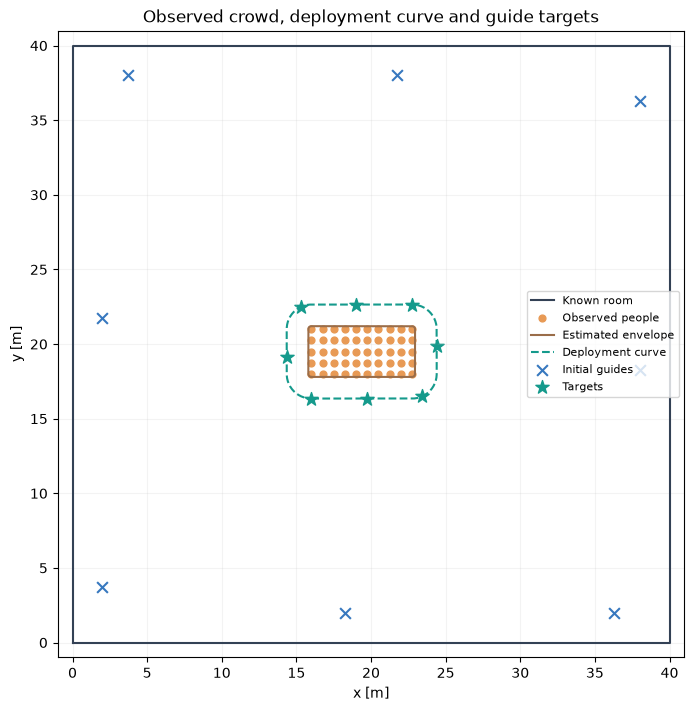

,target_id,x [m],y [m]
0,0,16.000,16.350
1,1,19.733,16.350
2,2,23.444,16.504
3,3,24.400,19.858
4,4,22.750,22.650
5,5,19.017,22.650
6,6,15.306,22.496
7,7,14.350,19.142


部署曲线长度：29.864 m
计划最大间隙：3.733 m


In [3]:
guide_cfg = config["guides"]
control_cfg = config["controller"]
safety = Safety(
    2*guide_cfg["radius"] + control_cfg["clearance"],
    guide_cfg["radius"] + float(observation.radii.max()) + control_cfg["clearance"],
    guide_cfg["radius"] + control_cfg["clearance"],
    guide_cfg["max_speed"], control_cfg["safety_numeric_tolerance"],
)
controller = ABCGController(control_cfg, safety, environment.scene.size)
controller.prepare(observation, initial_guides)

def closed_curve(points):
    return np.vstack([points, points[0]])

fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
room = np.array([[0, 0], [40, 0], [40, 40], [0, 40], [0, 0]])
ax.plot(*room.T, color="#334155", label="Known room")
ax.scatter(*observation.positions.T, s=24, color="#e89a55", label="Observed people")
ax.plot(*closed_curve(controller.boundary.crowd).T, color="#9a6d49", label="Estimated envelope")
ax.plot(*closed_curve(controller.boundary.deployment).T, "--", color="#159a8c", label="Deployment curve")
ax.scatter(*initial_guides.T, marker="x", color="#3778bf", s=60, label="Initial guides")
ax.scatter(*controller.plan.positions.T, marker="*", color="#159a8c", s=100, label="Targets")
ax.set(xlim=(-1, 41), ylim=(-1, 41), aspect="equal", xlabel="x [m]", ylabel="y [m]",
       title="Observed crowd, deployment curve and guide targets")
ax.legend(fontsize=8); ax.grid(alpha=.15)
plt.show()

display(pd.DataFrame({
    "target_id": np.arange(len(controller.plan.positions)),
    "x [m]": controller.plan.positions[:, 0],
    "y [m]": controller.plan.positions[:, 1],
}).round(3))
print(f"部署曲线长度：{controller.boundary.length:.3f} m")
print(f"计划最大间隙：{controller.plan.max_gap:.3f} m")

## 3. 执行闭环部署，并保存可复查证据

每一步：读取观测与 Guide 状态 → 跟踪路径 → 安全过滤 → 检查整个执行区间 → 更新 Guide。
运行器保存人员快照、轨迹、速度、目标、分配、规划历史和验收结果。

下面只调用统一运行器，不在 Notebook 中另写一套控制算法。
时间戳目录避免覆盖先前结果；再次运行会创建新目录。

In [4]:
from udc.experiments.runner import experiment, reevaluate_result

run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RESULT_DIR = PROJECT_ROOT / "runs" / f"notebook_static50_{run_id}"
metrics = experiment(CONFIG_PATH, RESULT_DIR, plots=True)
# 项目中的静态文件绘图使用 Agg；恢复 Notebook 的内嵌绘图后再展示后续图表。
plt.switch_backend("module://matplotlib_inline.backend_inline")
set_matplotlib_formats("png")
display(pd.DataFrame([
    {"指标": "终止状态", "结果": metrics["termination_status"]},
    {"指标": "实际 SUCCESS", "结果": metrics["success"]},
    {"指标": "活跃 Guide", "结果": metrics["active_guides"]},
    {"指标": "仿真时间 [s]", "结果": metrics["simulation_time"]},
    {"指标": "墙钟时间 [s]", "结果": round(metrics["wall_time"], 3)},
    {"指标": "执行步数", "结果": metrics["steps"]},
    {"指标": "人群严格静态", "结果": metrics["crowd_static"]},
    {"指标": "恢复次数", "结果": metrics["replan_count"]},
    {"指标": "安全求解 fallback 次数", "结果": metrics["fallback_count"]},
]))
print("结果目录：", RESULT_DIR.relative_to(PROJECT_ROOT).as_posix())
print("失败原因：", metrics["failure_reason"] or "无")

,指标,结果
0,终止状态,SUCCESS
1,实际 SUCCESS,True
2,活跃 Guide,8
3,仿真时间 [s],23.0
4,墙钟时间 [s],0.583
5,执行步数,230
6,人群严格静态,True
7,恢复次数,0
8,安全求解 fallback 次数,0


结果目录： runs/notebook_static50_20261014T010010_034537Z
失败原因： 无


## 4. 展示初态、运动过程与最终部署

下图使用已经执行并保存的轨迹。蓝色轨迹表示 Guide 的运动，星号表示规划目标。
人员位置在三幅图中相同；Guide 随时间靠近部署曲线。

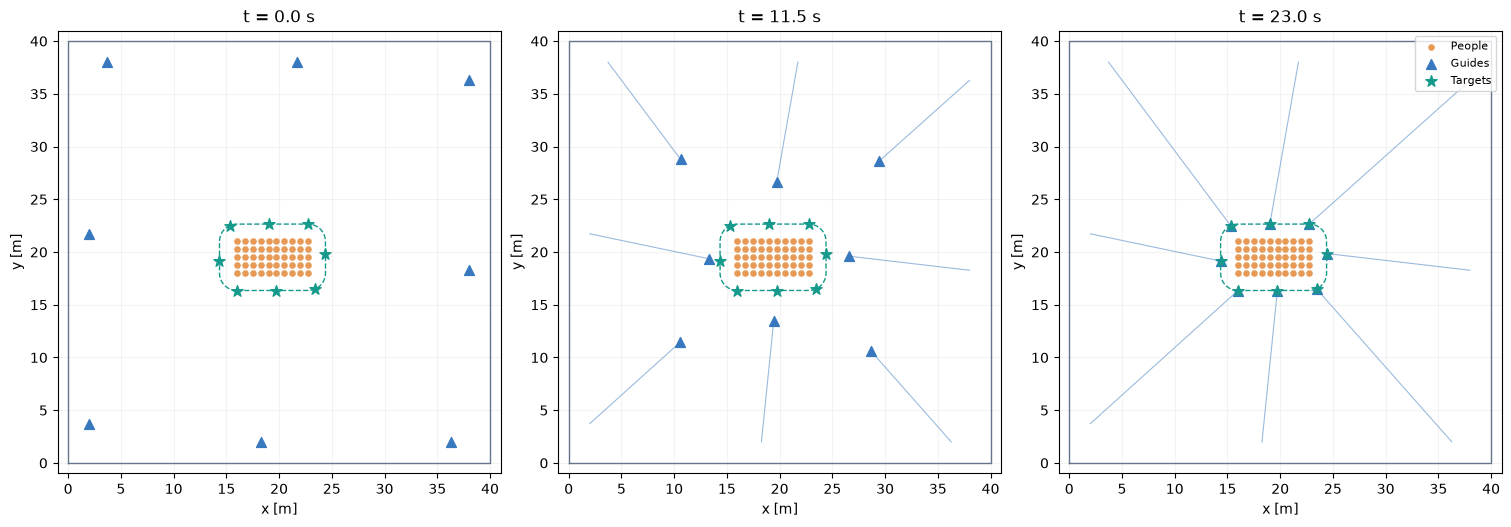

In [5]:
with np.load(RESULT_DIR / "trajectory.npz", allow_pickle=False) as saved:
    trace = {key: saved[key].copy() for key in saved.files}

trajectory = trace["positions"]
times = trace["time"]
people = trace["crowd_positions"]
targets = trace["targets"]
deployment = trace["boundary_deployment"]
indices = [0, len(times)//2, len(times)-1]
fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
for ax, frame in zip(axes, indices):
    ax.plot(*room.T, color="#64748b", linewidth=1)
    ax.scatter(*people.T, color="#e89a55", s=14, label="People")
    ax.plot(*closed_curve(deployment).T, "--", color="#159a8c", linewidth=1)
    for agent in range(trajectory.shape[1]):
        ax.plot(*trajectory[:frame+1, agent].T, color="#3778bf", alpha=.5, linewidth=.8)
    ax.scatter(*trajectory[frame].T, marker="^", color="#3778bf", s=50, label="Guides")
    ax.scatter(*targets.T, marker="*", color="#159a8c", s=70, label="Targets")
    ax.set(xlim=(-1, 41), ylim=(-1, 41), aspect="equal",
           xlabel="x [m]", ylabel="y [m]", title=f"t = {times[frame]:.1f} s")
    ax.grid(alpha=.15)
axes[-1].legend(fontsize=8, loc="upper right")
plt.show()

## 5. 检查到达：最大误差与速度都要满足条件

平均误差可能掩盖一个未到达的 Guide，因此同时展示最大误差与 RMSE。
成功还要求速度足够小，并连续保持指定步数；瞬间经过目标不算稳定到达。
图中的水平虚线是配置中冻结的判据，不通过调整它们来制造成功。

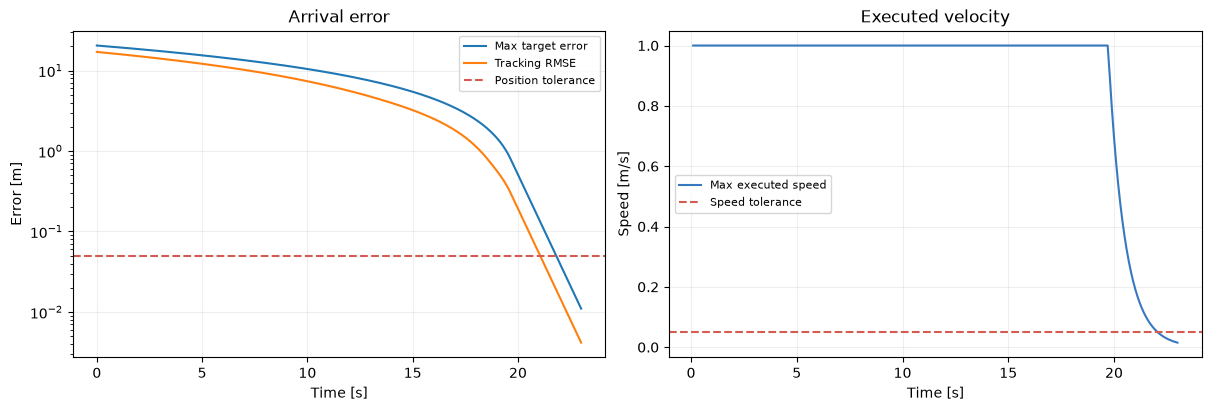

终点最大误差：0.01102 m；终点 RMSE：0.00416 m


In [6]:
active = trace["active_mask"]
assignment = trace["assignment"]
assigned_targets = targets[assignment[active]]
errors = np.linalg.norm(trajectory[:, active] - assigned_targets[None, :, :], axis=2)
max_error = errors.max(axis=1)
rmse = np.sqrt(np.mean(errors**2, axis=1))
speed = np.linalg.norm(trace["safe_velocity"][:, active], axis=2).max(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].semilogy(times, np.maximum(max_error, 1e-10), label="Max target error")
axes[0].semilogy(times, np.maximum(rmse, 1e-10), label="Tracking RMSE")
axes[0].axhline(control_cfg["position_tolerance"], color="#d45b52", linestyle="--", label="Position tolerance")
axes[0].set(xlabel="Time [s]", ylabel="Error [m]", title="Arrival error")
axes[1].plot(times[1:], speed, color="#3778bf", label="Max executed speed")
axes[1].axhline(control_cfg["speed_tolerance"], color="#d45b52", linestyle="--", label="Speed tolerance")
axes[1].set(xlabel="Time [s]", ylabel="Speed [m/s]", title="Executed velocity")
for ax in axes:
    ax.legend(fontsize=8); ax.grid(alpha=.2)
plt.show()
print(f"终点最大误差：{max_error[-1]:.5f} m；终点 RMSE：{rmse[-1]:.5f} m")

## 6. 检查覆盖与安全

覆盖同时要求 Guide 接近部署曲线，以及相邻 Guide 的最大弧长间隙不超过上限。
以下覆盖曲线由轨迹重新计算。初期 Guide 尚未到达，间隙曲线仅用于过程诊断，不能单独代表有效覆盖。

安全图展示整个采样执行区间上的**约束裕量**：中心最小距离减去对应的安全阈值。
裕量包含人体／Guide 半径和要求的 clearance，不能与单纯表面净距混淆。
非负裕量表示满足该数值模型中的要求；三种距离分别检查。

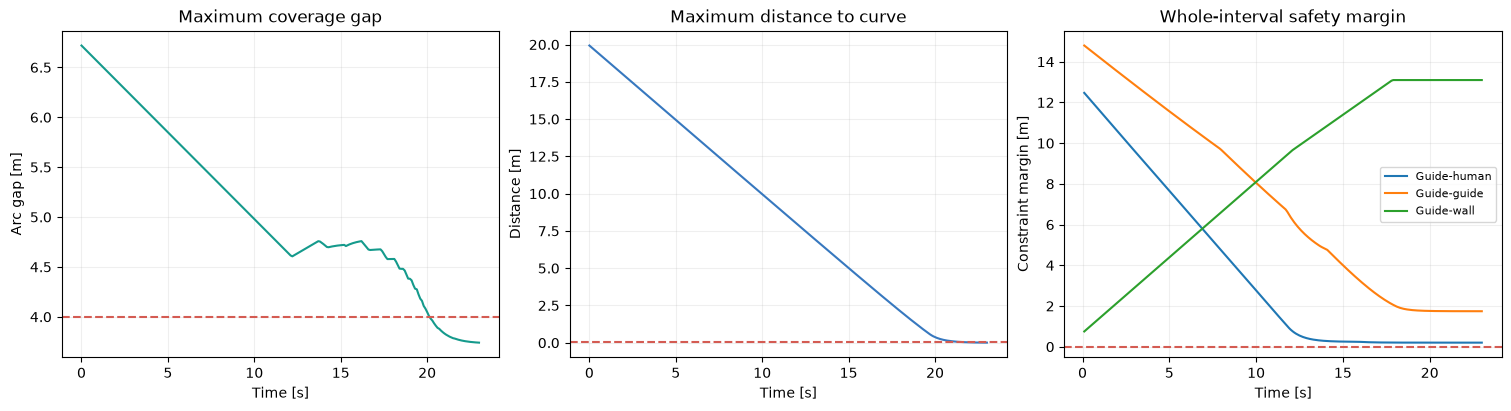

,指标,结果
0,最终最大弧长间隙 [m],3.7411
1,最终最大曲线距离 [m],0.0074
2,Guide-human 最小约束裕量 [m],0.2001
3,Guide-guide 最小约束裕量 [m],1.7434
4,Guide-wall 最小约束裕量 [m],0.7500


In [7]:
from shapely.geometry import Polygon, Point
from udc.controller.safety import path_clearances

line = Polygon(deployment).exterior
actual_gaps = []
curve_errors = []
for frame in trajectory[:, active]:
    arc = np.sort([line.project(Point(point)) for point in frame])
    actual_gaps.append(np.diff(np.r_[arc, arc[0]+line.length]).max())
    curve_errors.append(max(line.distance(Point(point)) for point in frame))

clearance_limits = {"crowd": safety.crowd_distance,
                    "guides": safety.guide_distance, "walls": safety.wall_distance}
margin_history = {key: [] for key in clearance_limits}
for start, end in zip(trajectory[:-1], trajectory[1:]):
    distances = path_clearances(start, end, people, trace["room"])
    for key in margin_history:
        margin_history[key].append(distances[key]-clearance_limits[key])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
axes[0].plot(times, actual_gaps, color="#159a8c")
axes[0].axhline(control_cfg["max_gap_limit"], color="#d45b52", linestyle="--")
axes[0].set(xlabel="Time [s]", ylabel="Arc gap [m]", title="Maximum coverage gap")
axes[1].plot(times, curve_errors, color="#3778bf")
axes[1].axhline(control_cfg["curve_tolerance"], color="#d45b52", linestyle="--")
axes[1].set(xlabel="Time [s]", ylabel="Distance [m]", title="Maximum distance to curve")
labels = {"crowd": "Guide-human", "guides": "Guide-guide", "walls": "Guide-wall"}
for key, values in margin_history.items():
    axes[2].plot(times[1:], values, label=labels[key])
axes[2].axhline(0., color="#d45b52", linestyle="--")
axes[2].set(xlabel="Time [s]", ylabel="Constraint margin [m]", title="Whole-interval safety margin")
axes[2].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=.2)
plt.show()
display(pd.DataFrame([
    {"指标": "最终最大弧长间隙 [m]", "结果": round(actual_gaps[-1], 4)},
    {"指标": "最终最大曲线距离 [m]", "结果": round(curve_errors[-1], 4)},
    *[{"指标": f"{labels[key]} 最小约束裕量 [m]", "结果": round(min(value), 4)}
      for key, value in margin_history.items()],
]))

## 7. 逐项验收并独立复判

实验成功必须同时满足几何、资源、目标规划、路径、安全、到达保持、曲线接近和覆盖间隙等条件。
下面先列出在线判定，再仅从保存的配置与轨迹复判。复判不重新运行控制器。
两者一致可以检查结果记录是否自洽，但共享的几何／距离工具仍需单元测试，不能据此声称完全独立的算法证明。

In [8]:
criterion_names = {
    "geometry_ok": "几何有效", "resource_ok": "资源与身份匹配",
    "plan_ok": "目标规划有效", "path_ok": "路径可达",
    "safety_ok": "历史区间安全", "arrival_ok": "到达并连续保持",
    "curve_ok": "接近部署曲线", "gap_ok": "实际间隙满足上限",
    "coverage_ok": "覆盖条件满足",
}
replay = reevaluate_result(RESULT_DIR)
display(pd.DataFrame([
    {"条件": criterion_names[key], "在线判定": value,
     "离线复判": replay["criteria"][key], "一致": value == replay["criteria"][key]}
    for key, value in metrics["criteria"].items()
]))
assert metrics["criteria"] == replay["criteria"], "在线和离线验收不一致。"
assert metrics["success"] == replay["success"], "SUCCESS 判定不一致。"
print("在线／离线 SUCCESS：", metrics["success"], "/", replay["success"])

,条件,在线判定,离线复判,一致
0,几何有效,True,True,True
1,资源与身份匹配,True,True,True
2,目标规划有效,True,True,True
3,路径可达,True,True,True
4,历史区间安全,True,True,True
5,到达并连续保持,True,True,True
6,接近部署曲线,True,True,True
7,实际间隙满足上限,True,True,True
8,覆盖条件满足,True,True,True


在线／离线 SUCCESS： True / True


## 8. 用 PedPy 分析人员空间分布

PedPy 分析的是人员密度和邻域；Guide 的部署评价由专用 evaluator 完成。
当前案例为冻结快照，因此不从这一帧讨论人员速度或流量。

分析中固定记录测量区域和 Voronoi 截断半径。区域整体平均可能掩盖局部差异，
下面再展示每个人的 Voronoi 单元密度。

,指标,结果
0,人数,50.000000
1,分析帧数,1.000000
2,经典区域密度 [person/m²],1.142857
3,Voronoi 区域密度 [person/m²],1.142857
4,Voronoi 截断半径 [m],1.000000


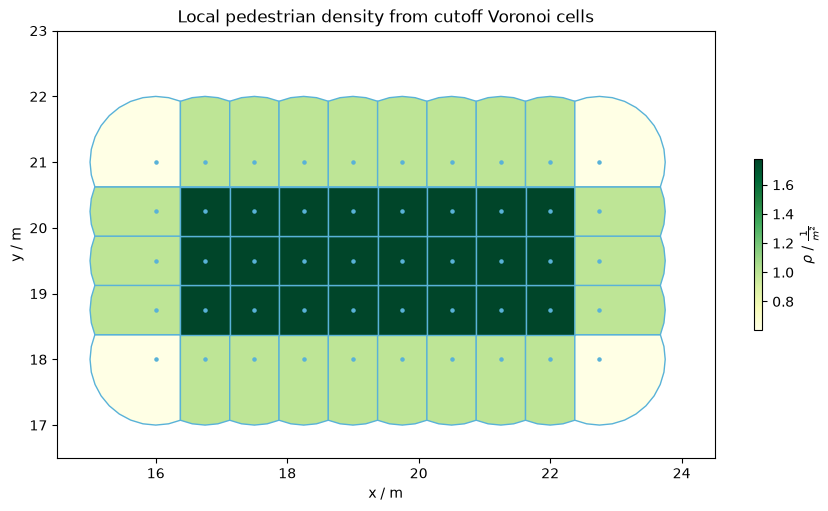

In [9]:
from udc.analysis.pedestrian import analyze
import pedpy

ANALYSIS_DIR = RESULT_DIR / "pedpy_analysis"
analysis_report = analyze(ANALYSIS_DIR, result=RESULT_DIR, cutoff_radius=1.0)
display(pd.DataFrame([
    {"指标": "人数", "结果": analysis_report["pedestrians"]},
    {"指标": "分析帧数", "结果": analysis_report["frames"]},
    {"指标": "经典区域密度 [person/m²]", "结果": analysis_report["mean_classic_density"]},
    {"指标": "Voronoi 区域密度 [person/m²]", "结果": analysis_report["mean_voronoi_density"]},
    {"指标": "Voronoi 截断半径 [m]", "结果": analysis_report["voronoi_cutoff_radius"]},
]))

pedestrian_trace = pedpy.TrajectoryData(pd.DataFrame({
    "id": np.arange(len(people)), "frame": np.zeros(len(people), dtype=int),
    "x": people[:, 0], "y": people[:, 1],
}), frame_rate=1.0/config["simulation"]["dt"])
walkable = pedpy.WalkableArea(environment.scene.polygon)
voronoi = pedpy.compute_individual_voronoi_polygons(
    traj_data=pedestrian_trace, walkable_area=walkable,
    cut_off=pedpy.Cutoff(radius=analysis_report["voronoi_cutoff_radius"], quad_segments=8),
)
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
pedpy.plot_voronoi_cells(voronoi_data=voronoi, traj_data=pedestrian_trace,
                        frame=0, walkable_area=walkable,
                        color_by_column=pedpy.DENSITY_COL, axes=ax)
ax.set(xlim=(14.5, 24.5), ylim=(16.5, 23.0), aspect="equal",
       title="Local pedestrian density from cutoff Voronoi cells")
plt.show()

**解读：** 网格中间与外围的 Voronoi 单元面积不同，因此局部密度可能不同。
本测量区域覆盖全部截断单元时，区域积分可使经典密度与 Voronoi 区域密度相同；
这不表示两种方法在任意区域都相同，也不表示外围密度估计与真实风险等价。
局部密度和 demand 是不同变量，本案例的 demand 均为 1，没有检验风险加权方法。

## 9. 自动生成本次实验结论与来源记录

下面的结论由当前运行结果生成。如果重新执行后出现失败，会报告失败状态及原因，而不是沿用成功结论。
报告同时记录代码与输入的哈希，便于追溯。仿真时间描述系统运动；墙钟时间受电脑性能影响。

In [10]:
if metrics["success"]:
    conclusion = (
        f"本固定案例中，{metrics['active_guides']} 个 Guide 在 **{metrics['simulation_time']:.1f} s** 仿真时间内"
        f"完成静态部署，终点最大误差为 **{metrics['max_tracking_error']:.4f} m**。"
        f"九类验收全部通过，保存轨迹的独立复判与在线判定一致。"
    )
else:
    conclusion = (
        f"本固定案例未完成全部验收，终止状态为 **{metrics['termination_status']}**。"
        f"失败原因：{metrics['failure_reason'] or '请查看逐项验收结果'}。"
    )
display(Markdown("### 本次结果" + chr(10)*2 + conclusion + chr(10)*2 +
                 "该结论仅适用于本案例；尚不能据此推断随机场景成功率、动态遏制效果或真实人群安全。"))
display(pd.DataFrame([
    {"记录": "源码 commit", "值": metrics["commit"]},
    {"记录": "工作树 dirty", "值": metrics["dirty"]},
    {"记录": "源码 SHA-256", "值": metrics["source_sha256"]},
    {"记录": "输入快照 SHA-256", "值": metrics["input_snapshot_sha256"]},
    {"记录": "配置 SHA-256", "值": metrics["config_sha256"]},
    {"记录": "任务 SHA-256", "值": metrics["task_sha256"]},
]))

### 本次结果

本固定案例中，8 个 Guide 在 **23.0 s** 仿真时间内完成静态部署，终点最大误差为 **0.0110 m**。九类验收全部通过，保存轨迹的独立复判与在线判定一致。

该结论仅适用于本案例；尚不能据此推断随机场景成功率、动态遏制效果或真实人群安全。

,记录,值
0,源码 commit,56f01979926cb4aef4d66d96fff2e3aee3a6b69f
1,工作树 dirty,True
2,源码 SHA-256,aaeb4d5c736945612a1ee5ea52e2fa92ae34b32481d827...
3,输入快照 SHA-256,d9c6dd5fd263556321164daa03260e7ae0be79be7fc977...
4,配置 SHA-256,168e981996f7120ec3e00c09eecc02c42e076ce6cfd2bd...
5,任务 SHA-256,5cfbc6b885afc0f01389f0fa5d55325be23c5a643da49b...


## 10. 下一步与报告提交

| 下一步 | 固定什么 | 改变什么 | 主要观察 |
|---|---|---|---|
| 同资源方法对照 | 人员快照、Guide 初态、安全判据、数量 | 部署规划方法 | 成功／失败、间隙、到达时间 |
| 资源压力 | 场景和方法 | Guide 数量 | 容量不足与运动失败的区别 |
| 边界估计对照 | 人员输入、规划与运动层 | 凸包、后续 alpha／radial | 保守程度、可行性和覆盖 |
| 多 seed 实验 | 冻结协议与评价器 | 独立随机输入 | 成功率与不确定性 |

先用少量开发 seed 诊断，再使用预先冻结的独立测试集。确定性网格重复运行不是新的统计样本。
尚未实现的多群、动态交互、风险模型与有限通信不能作为本报告的已完成贡献。

**提交建议：** 保留已执行输出，确认代码版本和失败记录后保存 `.ipynb`；
需要静态阅读版本时，可在 Jupyter 中导出 HTML。正式论文结果需要后续冻结协议、多 seed 和公平对照。

## 参考与代码

- [整合分支与运行说明](https://github.com/Wu-kaixin/Adaptive-Guide-Agent-Deployment-for-Unknown-Dynamic-Crowds/tree/integration/step1-framework)
- [报告依据提交 56f0197](https://github.com/Wu-kaixin/Adaptive-Guide-Agent-Deployment-for-Unknown-Dynamic-Crowds/tree/56f01979926cb4aef4d66d96fff2e3aee3a6b69f)
- [JuPedSim 官方文档](https://www.jupedsim.org/stable/index.html)：人群放置与后续动力学仿真。
- [PedPy 官方文档](https://pedpy.readthedocs.io/stable/index.html)：轨迹密度、速度、流量与邻域分析。
- [Vadere 官方网站](https://www.vadere.org/)：后续跨模型验证；本次实验没有使用 Vadere。